# Experiment 3: Regular Expression (Regex) Information Extraction & Pattern Validation System

### Problem Statement:
Design a text-processing system using Regular Expressions (Regex) to identify, extract, and validate patterns such as email addresses, URLs, phone numbers, dates, and hashtags from textual data.


In [1]:
import re
import datetime
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

print("Regex & data processing libraries imported successfully.")


Regex & data processing libraries imported successfully.


In [2]:
raw_corpus = (
    "Welcome to the AI Summit 2024! For registrations, contact Dr. Priya at priya.sharma@research-lab.org or "
    "support@nlp-conference.ai. You can also reach our administrative office at +91 98765-43210 or 022-28459012. "
    "US participants may call (555) 234-5678 or toll-free +1-800-555-0199. "
    "Detailed schedules are hosted at https://www.nlp-conference.ai/2024/schedule?session=deep_learning&track=nlp "
    "and auxiliary code repositories are accessible via http://github.com/nlp-lab/nlp-suite:8080/index.html. "
    "Important dates to note: abstract submission deadline is 2024-05-15, camera-ready papers are due on 12/06/2024, "
    "and final workshop proceedings will be presented on 25-Aug-2024. "
    "Join the conversation on Twitter/X using #NLPSummit2024 and #GenerativeAI, and tag our organizer @Jeet_Ghegade! "
    "Early bird registration ticket is $499.50, VIP passes cost €650.00, while student passes are priced at ₹5,000. "
    "Invalid edge cases to reject: user@@domain.com, https:///broken-url, +91-1234 (too short), 2024-13-45 (bad date)."
)

print(f"Corpus Character Length: {len(raw_corpus)}")
print("\n--- Corpus Excerpt ---")
print(raw_corpus[:350] + "...")


Corpus Character Length: 1008

--- Corpus Excerpt ---
Welcome to the AI Summit 2024! For registrations, contact Dr. Priya at priya.sharma@research-lab.org or support@nlp-conference.ai. You can also reach our administrative office at +91 98765-43210 or 022-28459012. US participants may call (555) 234-5678 or toll-free +1-800-555-0199. Detailed schedules are hosted at https://www.nlp-conference.ai/2024/...


In [3]:
PATTERNS = {
    "email": re.compile(r'''
        \b[a-zA-Z0-9_.+-]+          # Local part: alphanumeric, dot, underscore, plus, hyphen
        @
        [a-zA-Z0-9-]+               # Domain name
        (?:\.[a-zA-Z0-9-]+)*        # Optional subdomains
        \.[a-zA-Z]{2,63}\b         # Top-level domain (2 to 63 chars)
    ''', re.VERBOSE),

    "url": re.compile(r'''
        \b(?:https?|ftp)://        # Protocol
        (?:[a-zA-Z0-9-]+\.)+       # Subdomains and domain
        [a-zA-Z]{2,63}              # TLD
        (?::\d{2,5})?               # Optional Port (:8080)
        (?:/[^\s,;"'<>]*)*         # Path, query parameters, anchors
    ''', re.VERBOSE),

    "phone": re.compile(r'''
        (?:
            (?:\+\d{1,3}[-\s]?)?    # Optional International country code (+91, +1)
            (?:\(?\d{2,5}\)?[-\s]?) # Area code or std code: (555), 022, 98765
            \d{3,5}[-\s]?\d{4}      # Remaining 7 to 10 subscriber digits
        )
    ''', re.VERBOSE),

    "date": re.compile(r'''
        \b(?:
            \d{4}[-/]\d{2}[-/]\d{2}           # ISO: YYYY-MM-DD or YYYY/MM/DD
            |
            \d{2}[-/]\d{2}[-/]\d{4}           # Standard: DD/MM/YYYY or MM/DD/YYYY
            |
            \d{1,2}-(?:Jan|Feb|Mar|Apr|May|Jun| # Written: DD-Mon-YYYY
                     Jul|Aug|Sep|Oct|Nov|Dec)-\d{4}
            |
            (?:Jan|Feb|Mar|Apr|May|Jun|          # Written: Mon DD, YYYY
               Jul|Aug|Sep|Oct|Nov|Dec)\s+\d{1,2},\s+\d{4}
        )\b
    ''', re.VERBOSE),

    "hashtag": re.compile(r'#([a-zA-Z0-9_]{2,50})'),
    "mention": re.compile(r'@([a-zA-Z0-9_]{2,50})'),
    "currency": re.compile(r'[$€£₹]\s?\d{1,3}(?:,\d{3})*(?:\.\d{2})?')
}

print("All regex patterns successfully compiled with verbose flags.")


All regex patterns successfully compiled with verbose flags.


In [4]:
class RegexInformationExtractor:
    def __init__(self, patterns):
        self.patterns = patterns

    def extract_all(self, text):
        results = {}
        for pattern_name, regex in self.patterns.items():
            matches = regex.findall(text)
            # Flatten tuples if groups were present
            cleaned_matches = []
            for m in matches:
                if isinstance(m, tuple):
                    cleaned_matches.append([x for x in m if x][0])
                else:
                    cleaned_matches.append(m.strip())
            results[pattern_name] = cleaned_matches
        return results

    def validate_date(self, date_str):
        formats = [
            "%Y-%m-%d", "%Y/%m/%d",
            "%d/%m/%Y", "%m/%d/%Y",
            "%d-%b-%Y", "%b %d, %Y"
        ]
        for fmt in formats:
            try:
                parsed = datetime.datetime.strptime(date_str, fmt)
                return True, parsed.strftime("%Y-%m-%d (ISO)")
            except ValueError:
                continue
        return False, "Invalid Calendar Date"

    def validate_phone(self, phone_str):
        # Clean delimiters
        digits = re.sub(r'\D', '', phone_str)
        if 10 <= len(digits) <= 15:
            return True, f"Valid ({len(digits)} digits)"
        return False, f"Invalid length ({len(digits)} digits)"

    def validate_email(self, email_str):
        parts = email_str.split('@')
        if len(parts) == 2 and '.' in parts[1]:
            domain_ext = parts[1].split('.')[-1]
            if len(domain_ext) >= 2:
                return True, f"Valid TLD (.{domain_ext})"
        return False, "Invalid Domain Structure"

extractor = RegexInformationExtractor(PATTERNS)
raw_extractions = extractor.extract_all(raw_corpus)

for category, items in raw_extractions.items():
    print(f"[{category.upper()}] ({len(items)} found):")
    for item in items:
        print(f"  - {item}")
    print()


[EMAIL] (2 found):
  - priya.sharma@research-lab.org
  - support@nlp-conference.ai

[URL] (2 found):
  - https://www.nlp-conference.ai/2024/schedule?session=deep_learning&track=nlp
  - http://github.com/nlp-lab/nlp-suite:8080/index.html.

[PHONE] (4 found):
  - +91 98765-4321
  - 022-28459012
  - (555) 234-5678
  - +1-800-555-0199

[DATE] (4 found):
  - 2024-05-15
  - 12/06/2024
  - 25-Aug-2024
  - 2024-13-45

[HASHTAG] (2 found):
  - NLPSummit2024
  - GenerativeAI

[MENTION] (4 found):
  - research
  - nlp
  - Jeet_Ghegade
  - domain

[CURRENCY] (3 found):
  - $499.50
  - €650.00
  - ₹5,000



In [5]:
validation_records = []

# Validate Emails
for email in raw_extractions['email']:
    is_valid, reason = extractor.validate_email(email)
    validation_records.append({"Type": "Email", "Value": email, "Is Valid": is_valid, "Note": reason})

# Validate Phones
for phone in raw_extractions['phone']:
    is_valid, reason = extractor.validate_phone(phone)
    validation_records.append({"Type": "Phone", "Value": phone, "Is Valid": is_valid, "Note": reason})

# Validate Dates
for dt in raw_extractions['date']:
    is_valid, reason = extractor.validate_date(dt)
    validation_records.append({"Type": "Date", "Value": dt, "Is Valid": is_valid, "Note": reason})

df_validation = pd.DataFrame(validation_records)
print("--- Extracted Entity Validation Report ---")
print(df_validation.to_string(index=False))


--- Extracted Entity Validation Report ---
 Type                         Value  Is Valid                  Note
Email priya.sharma@research-lab.org      True      Valid TLD (.org)
Email     support@nlp-conference.ai      True       Valid TLD (.ai)
Phone                +91 98765-4321      True     Valid (11 digits)
Phone                  022-28459012      True     Valid (11 digits)
Phone                (555) 234-5678      True     Valid (10 digits)
Phone               +1-800-555-0199      True     Valid (11 digits)
 Date                    2024-05-15      True      2024-05-15 (ISO)
 Date                    12/06/2024      True      2024-06-12 (ISO)
 Date                   25-Aug-2024      True      2024-08-25 (ISO)
 Date                    2024-13-45     False Invalid Calendar Date


In [6]:
def anonymize_text(text, patterns):
    redacted = text
    # 1. Redact emails
    redacted = patterns['email'].sub('[REDACTED_EMAIL]', redacted)
    # 2. Redact phones
    redacted = patterns['phone'].sub('[REDACTED_PHONE]', redacted)
    # 3. Redact currency
    redacted = patterns['currency'].sub('[REDACTED_AMOUNT]', redacted)
    return redacted

anonymized_corpus = anonymize_text(raw_corpus, PATTERNS)

print("--- Original Text Excerpt ---")
print(raw_corpus[90:380])
print("\n--- Anonymized / Redacted Text Excerpt ---")
print(anonymized_corpus[90:380])


--- Original Text Excerpt ---
ch-lab.org or support@nlp-conference.ai. You can also reach our administrative office at +91 98765-43210 or 022-28459012. US participants may call (555) 234-5678 or toll-free +1-800-555-0199. Detailed schedules are hosted at https://www.nlp-conference.ai/2024/schedule?session=deep_learning

--- Anonymized / Redacted Text Excerpt ---
 [REDACTED_EMAIL]. You can also reach our administrative office at [REDACTED_PHONE]0 or [REDACTED_PHONE]. US participants may call [REDACTED_PHONE] or toll-free [REDACTED_PHONE]. Detailed schedules are hosted at https://www.nlp-conference.ai/2024/schedule?session=deep_learning&track=nlp an


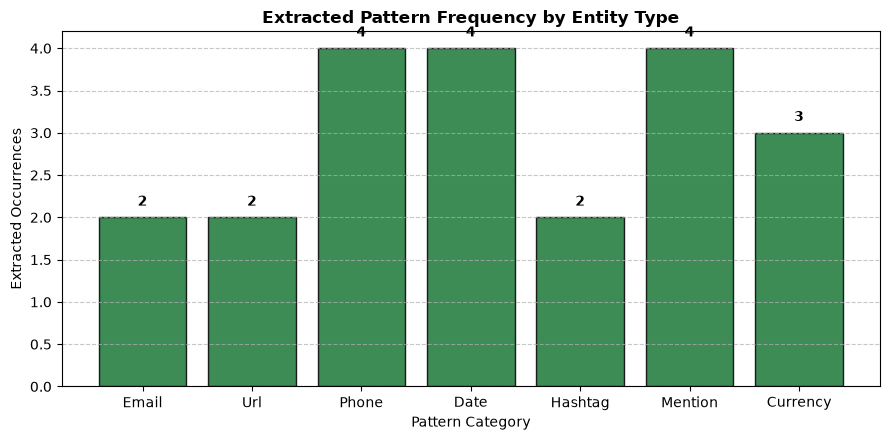

In [7]:
counts = {cat.capitalize(): len(items) for cat, items in raw_extractions.items()}

plt.figure(figsize=(9, 4.5))
bars = plt.bar(counts.keys(), counts.values(), color='#1b7837', edgecolor='black', alpha=0.85)
plt.title("Extracted Pattern Frequency by Entity Type", fontsize=12, fontweight='bold')
plt.xlabel("Pattern Category", fontsize=10)
plt.ylabel("Extracted Occurrences", fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.1, int(yval), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()
